# Scam losses: where do they concentrate, and where should a bank add friction?

**Reader:** head of fraud strategy at a large US bank. **Decision:** where in the payment flow to add friction (warnings, delays, confirmation steps).
**Data:** FTC Consumer Sentinel Data Books 2019 to 2024 (aggregate tables, extracted from the published PDFs) and the CFPB Consumer Complaint Database (record level). The plan, method and predictions were written before the analysis in [research_plan.md](../research_plan.md). Both sources are **unverified consumer reports** that cover only a fraction of scams.

## Answer in brief
- **A few large losses are most of the money.** In 2024, 12.6% of loss reports were above $10,000 and held at least **87.6%** of the $12.5 billion reported. The typical (median) loss was $497; the average was 25 times larger.
- **Bank transfers and crypto dominate the dollars.** Together with wires they were **70%** of classified payment-method losses in 2024, and a bank-transfer report carries about **$44,000** in losses, 17 times a credit-card report.
- **Total and typical loss rank channels differently.** Social media has the highest total losses ($1.86B) but a median of $409; phone calls have the highest median ($1,500).
- **Banks rarely reimburse scam victims, and they differ a lot.** Only **6.3%** of CFPB scam complaints ended in monetary relief; company rates range from 0% to 20%, and 15 of 29 large companies sit outside what chance would produce.
- **Whether friction pays depends mostly on who bears the loss.** For bank transfers, friction (25% effective, $5 per flagged payment) pays off if about 1 in 140 flagged payments is a scam when the bank bears only today's 6.3% of losses, but at about 1 in 2,200 when the bank reimburses in full, a 16-fold difference.

In [1]:
import sys, warnings; sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scam

NAVY, ORANGE, GREY, RED, TEAL = "#2f4b7c", "#e08b3a", "#8a8f98", "#c0504d", "#4aa3a2"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../reports/figures/"
ftc = scam.load_ftc(); pop = scam.population()
tot = ftc["totals"].set_index("year")

## 1. Reported losses over time

In [2]:
t = tot.copy()
t["loss_billion"] = t.total_loss / 1e9
t["loss_per_100k"] = t.total_loss / pop.reindex(t.index) * 1e5
t["share_reports_with_loss"] = t.reports_with_loss / t.fraud_reports
t["mean_loss_per_loss_report"] = t.total_loss / t.reports_with_loss
t["mean_to_median"] = t.mean_loss_per_loss_report / t.median_loss
show = t[["fraud_reports", "share_reports_with_loss", "loss_billion", "loss_per_100k", "median_loss", "mean_loss_per_loss_report", "mean_to_median"]]
print(show.round(2).to_string())
print(f"\n2019 to 2024: total reported loss x{t.total_loss.iloc[-1] / t.total_loss.iloc[0]:.1f}; per 100,000 residents x{t.loss_per_100k.iloc[-1] / t.loss_per_100k.iloc[0]:.1f}; median loss x{t.median_loss.iloc[-1] / t.median_loss.iloc[0]:.2f}; reports x{t.fraud_reports.iloc[-1] / t.fraud_reports.iloc[0]:.2f}")

      fraud_reports  share_reports_with_loss  loss_billion  loss_per_100k  median_loss  mean_loss_per_loss_report  mean_to_median
year                                                                                                                             
2019        1697934                     0.23          1.90      579169.85          320                    4892.24           15.29
2020        2184531                     0.34          3.31      996874.24          311                    4451.20           14.31
2021        2789161                     0.25          5.89     1774545.21          500                    8511.65           17.02
2022        2369527                     0.26          8.77     2624824.00          650                   14384.97           22.13
2023        2566261                     0.27         10.02     2975391.81          500                   14502.95           29.01
2024        2600678                     0.38         12.54     3686206.90          497    

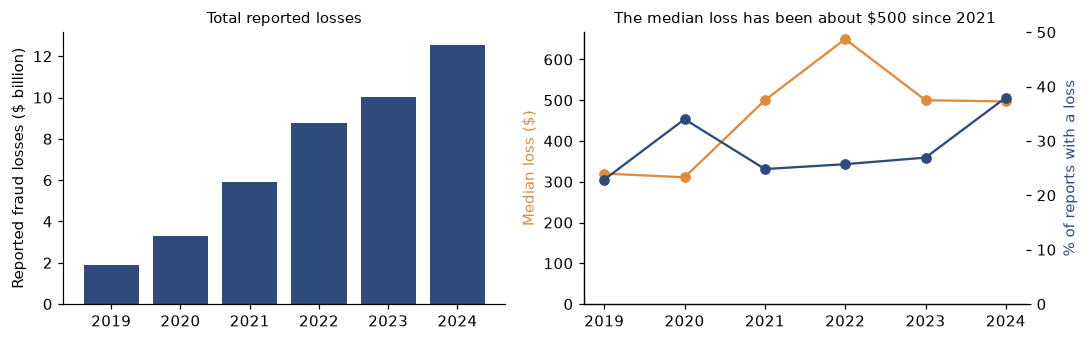

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(t.index, t.loss_billion, color=NAVY); ax[0].set_ylabel("Reported fraud losses ($ billion)"); ax[0].set_title("Total reported losses", fontsize=10)
ax[1].plot(t.index, t.median_loss, color=ORANGE, marker="o", label="Median loss"); ax[1].set_ylabel("Median loss ($)", color=ORANGE); ax[1].set_ylim(0)
a2 = ax[1].twinx(); a2.plot(t.index, 100 * t.share_reports_with_loss, color=NAVY, marker="o"); a2.set_ylabel("% of reports with a loss", color=NAVY); a2.set_ylim(0, 50)
ax[1].set_title("The median loss has been about $500 since 2021", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "trend.png"); plt.show()

Reported losses rose from $1.9 billion in 2019 to $12.5 billion in 2024: **6.6 times**, or **6.4 times per resident** ($5.79 to $36.86 per person, using Census population). Reports rose only 1.5 times, so the money per report grew far faster than the count. The median loss moved from $320 to about $500 and has been roughly flat since 2021, while the mean loss per loss report went from about $4,900 to $12,700. The share of reports that include a loss jumped around (23% to 38%), which can reflect how reports are collected as well as what happens to victims, so I don't read a trend into it.

## 2. A few large losses are most of the money
Totals can mislead when losses are this skewed, so medians sit beside means. The FTC publishes how many loss reports fall in each dollar band. The reports in the lower bands cannot have lost more than each band's upper limit, which gives a **lower bound** on the dollar share held by reports above $10,000.

In [4]:
b = ftc["loss_buckets"]
bound = scam.tail_share_lower_bound(b, tot.total_loss)
top = b[b.high.isna()].set_index("year").reports
dist = pd.DataFrame({"share_of_loss_reports_above_10k": top / tot.reports_with_loss, "dollar_share_lower_bound": bound})
print((100 * dist).round(1).to_string())
y = 2024; g = b[b.year == y].copy(); g["share"] = g.reports / g.reports.sum()
print(f"\n{y}: {g.share.iloc[-1]:.1%} of loss reports exceed $10,000 and hold at least {bound[y]:.1%} of all dollars lost; {g.share.iloc[0]:.0%} lost $1,000 or less")

      share_of_loss_reports_above_10k  dollar_share_lower_bound
2019                              6.0                      69.4
2020                              5.4                      65.6
2021                              9.5                      80.9
2022                             14.1                      88.5
2023                             14.2                      89.0
2024                             12.6                      87.6

2024: 12.6% of loss reports exceed $10,000 and hold at least 87.6% of all dollars lost; 63% lost $1,000 or less


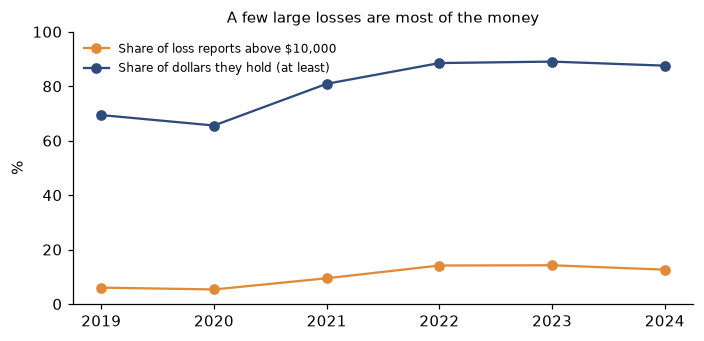

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
yrs = dist.index
ax.plot(yrs, 100 * dist.share_of_loss_reports_above_10k, marker="o", color=ORANGE, label="Share of loss reports above $10,000")
ax.plot(yrs, 100 * dist.dollar_share_lower_bound, marker="o", color=NAVY, label="Share of dollars they hold (at least)")
ax.set_ylim(0, 100); ax.set_ylabel("%"); ax.legend(frameon=False, fontsize=8); ax.set_title("A few large losses are most of the money", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "tail.png"); plt.show()

In 2024, **12.6% of loss reports exceeded $10,000 and held at least 87.6% of the dollars**; 63% lost $1,000 or less. The concentration has grown: in 2019, 6.0% of loss reports held at least 69%. For a fraud-strategy lead this splits the job in two: controls that stop a handful of very large transfers move most of the dollars, while the typical victim loses about $500, a customer-service and communication problem more than a payment-control problem.

## 3. By payment method (2020 to 2024)
The FTC reports the number of reports and total dollars for each payment method (but not the median). I compare each method's share of classified dollars, and the dollars per report.

In [6]:
p = ftc["payment_method"]; p = p[p.year >= 2020].copy()
p["method"] = p.method.replace({"Cash or Cash Advance": "Cash", "Other": "Other"})
p = p[p.method != "Other"]
piv = p.pivot(index="method", columns="year", values="total_loss_musd")
share = (100 * piv / piv.sum()).round(1)
cov = pd.DataFrame({"payment-method classified $M": piv.sum(), "all fraud $M": tot.total_loss.loc[2020:] / 1e6})
cov["coverage"] = (cov.iloc[:, 0] / cov.iloc[:, 1]).round(2)
rep = p.pivot(index="method", columns="year", values="reports")
n_pm = ftc["totals"].set_index("year").fraud_reports
print("Share of classified payment-method dollars (%):"); print(share.sort_values(2024, ascending=False).to_string())
print("\nCoverage of payment-method totals relative to all reported fraud dollars:"); print(cov.round(2).to_string())
lpr = (piv * 1e6 / rep).round(0)
print("\nLoss per report ($) = total dollars / all reports with that payment method:"); print(lpr.sort_values(2024, ascending=False).to_string())
big3 = piv.loc[["Bank Transfer or Payment", "Cryptocurrency", "Wire Transfer"]].sum() / piv.sum()
print("\nBank transfer + crypto + wire share of classified dollars:", (100 * big3).round(0).to_dict())

Share of classified payment-method dollars (%):
year                      2020  2021  2022  2023  2024
method                                                
Bank Transfer or Payment  21.1  24.8  34.6  37.0  38.4
Cryptocurrency             8.7  24.6  31.2  28.0  26.1
Payment App or Service     5.8   4.3   3.6   4.2   7.2
Cash                       9.8   6.2   5.1   5.4   5.7
Wire Transfer             20.9  15.8   6.8   6.8   5.3
Credit Cards              10.0   5.9   4.8   4.9   5.1
Check                      5.8   5.0   3.9   4.2   4.1
Gift Card or Reload Card   8.3   7.6   5.0   4.3   3.9
Debit Card                 7.9   4.6   4.3   4.4   3.3
Money Order                1.7   1.3   0.9   0.9   0.9

Coverage of payment-method totals relative to all reported fraud dollars:
      payment-method classified $M  all fraud $M  coverage
year                                                      
2020                          1490       3305.41      0.45
2021                          3052      

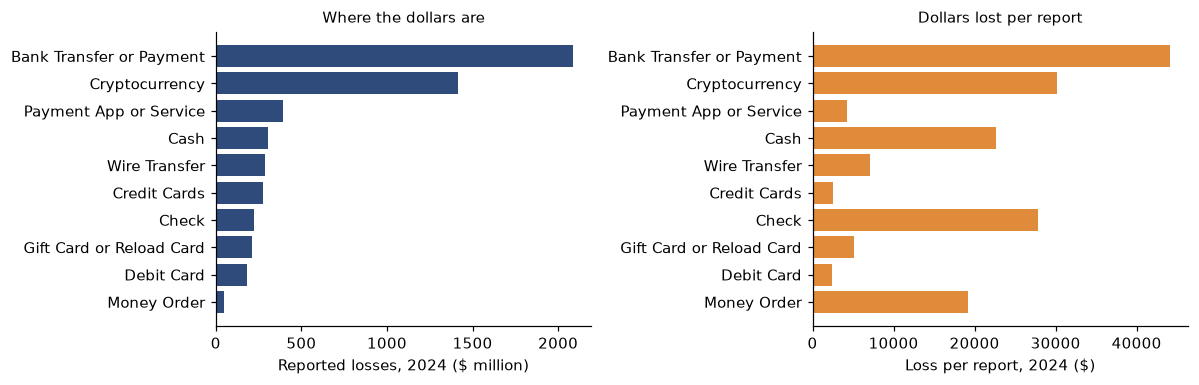

In [7]:
order = share.sort_values(2024, ascending=True).index
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].barh(order, piv.loc[order, 2024], color=NAVY); ax[0].set_xlabel("Reported losses, 2024 ($ million)"); ax[0].set_title("Where the dollars are", fontsize=10)
ax[1].barh(order, lpr.loc[order, 2024], color=ORANGE); ax[1].set_xlabel("Loss per report, 2024 ($)"); ax[1].set_title("Dollars lost per report", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "payment_method.png"); plt.show()

- **The mix shifted to bank transfers and crypto.** Bank transfer or payment went from 21% of classified dollars in 2020 to 38% in 2024; cryptocurrency from 9% to 26% (peaking at 31% in 2022); wire transfers fell from 21% to 5%. Together with wires, these three were **70%** in 2024.
- **Dollars per report differ by more than an order of magnitude.** Bank transfer: **$44,131** per report in 2024 (up from $18,428 in 2020), crypto $30,214, against $2,526 for credit cards and $2,360 for debit cards: **17 times** between bank transfers and credit cards. Because this divides by all reports with that method (some without a loss), it understates the average loss when a loss happens.
- **Coverage:** payment method is identified for only 18% of fraud reports, yet those reports account for 43% to 52% of all reported dollars. Reports that name a payment method skew toward large losses, so shares here describe classified losses, not all scams.

## 4. By contact method (2020 to 2024)

In [8]:
c = ftc["contact_method"]; c = c[c.year >= 2020].copy(); c["method"] = c.method.replace({"E-mail": "Email"})
c24 = c[c.year == 2024].set_index("method")[["reports", "total_loss_musd", "median_loss"]].sort_values("total_loss_musd", ascending=False)
c24["mean_loss_per_report"] = (c24.total_loss_musd * 1e6 / c24.reports).round(0)
print(c24.to_string())
print("\nRank by total dollars:", list(c24.index)); print("Rank by median loss :", list(c24.sort_values("median_loss", ascending=False).index))

                     reports  total_loss_musd  median_loss  mean_loss_per_report
method                                                                          
Social Media          186826             1858          409                9945.0
Other                 148288             1072          633                7229.0
Website or Apps       186663              976          200                5229.0
Phone call            284659              948         1500                3330.0
Email                 371651              502          600                1351.0
Text                  246784              470         1000                1904.0
Online Ad or Pop-up    42023              246          180                5854.0
Mail                   42108               90          990                2137.0

Rank by total dollars: ['Social Media', 'Other', 'Website or Apps', 'Phone call', 'Email', 'Text', 'Online Ad or Pop-up', 'Mail']
Rank by median loss : ['Phone call', 'Text', 'Mail', 'Other

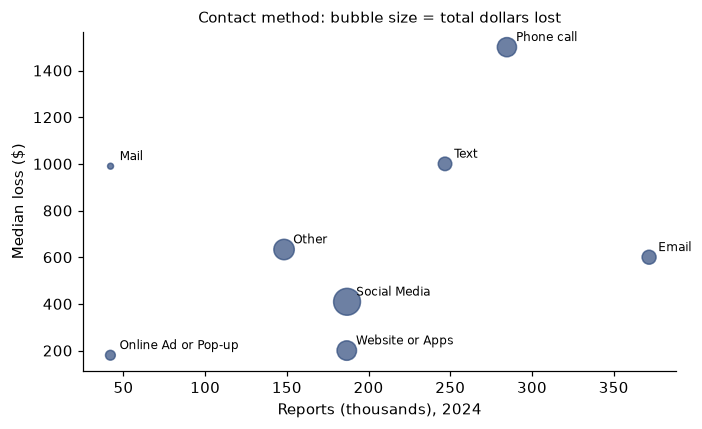

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(c24.reports / 1e3, c24.median_loss, s=c24.total_loss_musd / 6, color=NAVY, alpha=0.7)
for m, r in c24.iterrows(): ax.annotate(m, (r.reports / 1e3, r.median_loss), fontsize=8, xytext=(6, 4), textcoords="offset points")
ax.set_xlabel("Reports (thousands), 2024"); ax.set_ylabel("Median loss ($)"); ax.set_title("Contact method: bubble size = total dollars lost", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "contact_method.png"); plt.show()

In 2024 **social media had the highest total losses ($1.86B) but a median of only $409; phone calls had the highest median ($1,500) yet ranked fourth by total ($948M).** Text messages ($1,000 median) and mail ($990) also rank higher by typical loss than by total. The channels with the highest totals (social media, website or apps) have a mean loss per report of $5,000 to $10,000 against medians of $200 to $409, which signals a tail of very large losses (investment and romance scams) behind the totals, while the phone and text rankings reflect steady mid-size losses. The channel is mostly invisible to a bank at payment time, so it is useful for customer education and risk profiling more than for a payment rule.

## 5. How do banks respond when customers complain about a scam?
The CFPB tags scams as the issue "Fraud or scam" within the money transfer product (the product that holds Zelle, Cash App, PayPal, wires and crypto exchanges). Complaints from 2023 to the last complete week are compared with "Unauthorized transactions" complaints in the same product. **Self-selection caveat:** only customers who are unhappy enough to complain are in the data, so these are rates among complainers, not among scam victims, and they do not measure which bank protects customers better.

In [10]:
raw = pd.read_parquet(scam.CFPB, columns=["date_received", "product", "issue", "company", "company_response_to_consumer", "timely_response"])
for col in ["product", "issue", "company", "company_response_to_consumer", "timely_response"]: raw[col] = raw[col].astype(str)
mt = raw[(raw["product"] == "Money transfer, virtual currency, or money service") & (raw.date_received >= "2023-01-01") & (raw.date_received < "2026-10-12")]
sc = mt[mt.issue == "Fraud or scam"].copy(); un = mt[mt.issue == "Unauthorized transactions or other transaction problem"].copy()
allsc = raw[(raw.issue == "Fraud or scam") & (raw["product"] == "Money transfer, virtual currency, or money service") & (raw.date_received >= "2019-01-01")]
print("Scam complaints (money transfer product, issue 'Fraud or scam') by year:"); print(allsc.groupby(allsc.date_received.dt.year).size().to_string())
def summ(x):
    r = x.company_response_to_consumer
    return pd.Series({"n": len(x), "monetary": (r == "Closed with monetary relief").sum(), "nonmonetary": (r == "Closed with non-monetary relief").sum(),
                      "explanation": (r == "Closed with explanation").sum(), "untimely": (x.timely_response == "No").sum()})
overall = summ(sc); overall_un = summ(un)
print(f"\nSince 2023: {int(overall.n):,} scam complaints | monetary relief {overall.monetary / overall.n:.1%}, non-monetary {overall.nonmonetary / overall.n:.1%}, explanation only {overall.explanation / overall.n:.1%}, untimely {overall.untimely / overall.n:.1%}")
print(f"Unauthorized-transaction complaints for comparison: {int(overall_un.n):,} | monetary relief {overall_un.monetary / overall_un.n:.1%}, non-monetary {overall_un.nonmonetary / overall_un.n:.1%}")
yr = sc.groupby(sc.date_received.dt.year).apply(lambda x: (x.company_response_to_consumer == "Closed with monetary relief").mean())
print("\nMonetary relief rate by year:", yr.round(3).to_dict())

Scam complaints (money transfer product, issue 'Fraud or scam') by year:
date_received
2019     1914
2020     2398
2021     3804
2022     5933
2023     5395
2024     6173
2025    11179
2026     9329

Since 2023: 31,959 scam complaints | monetary relief 6.3%, non-monetary 2.8%, explanation only 89.7%, untimely 1.9%
Unauthorized-transaction complaints for comparison: 14,545 | monetary relief 10.8%, non-monetary 4.4%

Monetary relief rate by year: {2023: 0.07, 2024: 0.069, 2025: 0.049, 2026: 0.073}


In [11]:
co = sc.groupby("company").apply(summ); co = co[co.n >= 100].copy()
co["monetary_rate"] = co.monetary / co.n; co["any_relief_rate"] = (co.monetary + co.nonmonetary) / co.n
co["lo"], co["hi"] = scam.wilson(co.monetary, co.n)
p0 = overall.monetary / overall.n
co["z"] = (co.monetary_rate - p0) / np.sqrt(p0 * (1 - p0) / co.n)
un_co = un.groupby("company").apply(summ); co["unauth_monetary_rate"] = (un_co.monetary / un_co.n).reindex(co.index); co["unauth_n"] = un_co.n.reindex(co.index)
out = co.sort_values("n", ascending=False)
out[["n", "monetary_rate", "lo", "hi", "any_relief_rate", "z", "unauth_n", "unauth_monetary_rate"]].round(3)

,n,monetary_rate,lo,hi,any_relief_rate,z,unauth_n,unauth_monetary_rate
company,,,,,,,,
"Block, Inc.",6482,0.000,0.000,0.001,0.000,-20.828,5993,0.001
"Paypal Holdings, Inc",3734,0.200,0.187,0.213,0.342,34.393,4475,0.283
JPMORGAN CHASE & CO.,2896,0.035,0.028,0.042,0.042,-6.309,435,0.076
WELLS FARGO & COMPANY,2867,0.043,0.036,0.051,0.063,-4.356,331,0.085
"BANK OF AMERICA, NATIONAL ASSOCIATION",2349,0.187,0.172,0.203,0.195,24.706,244,0.221
"Early Warning Services, LLC",2082,0.000,-0.000,0.002,0.000,-11.833,603,0.000
Chime Financial Inc,1481,0.035,0.027,0.046,0.048,-4.420,824,0.047
"Coinbase, Inc.",1111,0.104,0.088,0.124,0.106,5.678,68,0.265
"CITIBANK, N.A.",544,0.094,0.072,0.121,0.129,2.950,29,0.172


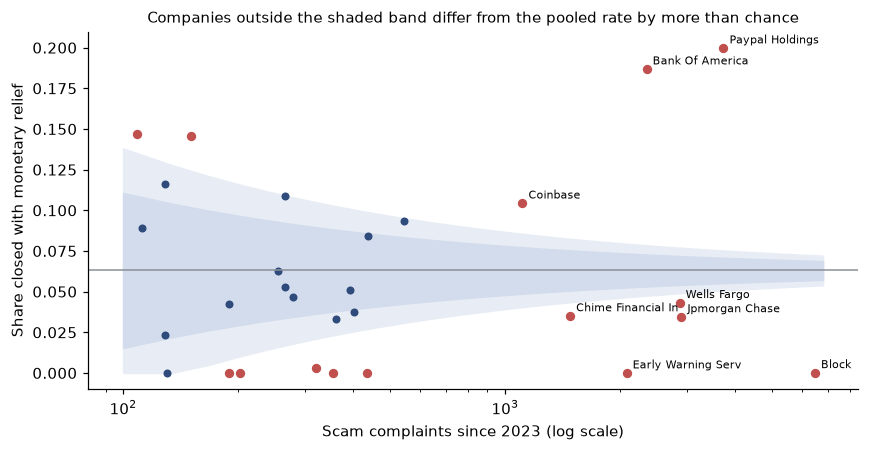

Pooled monetary relief rate 6.3%. Companies with at least 100 scam complaints: 29; outside the 95% limits: 21; outside the 99.8% limits: 15
Above the limits: ['BANK OF AMERICA, NATIONAL ASSOCIATION', 'CITIZENS FINANCIAL GROUP, INC.', 'Coinbase, Inc.', 'DISCOVER BANK', 'Paypal Holdings, Inc']
Below the limits: ['Block, Inc.', 'Chime Financial Inc', 'Early Warning Services, LLC', 'Foris DAX, Inc.', 'JPMORGAN CHASE & CO.', 'Payward Ventures Inc. dba Kraken', 'ROBINHOOD MARKETS INC.', 'Remitly, Inc.', 'WELLS FARGO & COMPANY', 'WESTERN UNION COMPANY, THE']


In [12]:
lim_n = np.linspace(100, co.n.max() * 1.05, 200)
lo95, hi95 = scam.funnel_limits(p0, lim_n, 1.96); lo99, hi99 = scam.funnel_limits(p0, lim_n, 3.09)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.fill_between(lim_n, lo99, hi99, color="#e8edf5"); ax.fill_between(lim_n, lo95, hi95, color="#d3dcec")
ax.axhline(p0, color=GREY, lw=1)
out_flag = co.z.abs() > 3.09
ax.scatter(co.n[~out_flag], 100 * 0 + co.monetary_rate[~out_flag], color=NAVY, s=18); ax.scatter(co.n[out_flag], co.monetary_rate[out_flag], color=RED, s=26)
for name, r in co[(co.n > 1000) | (co.monetary_rate > 0.15)].iterrows(): ax.annotate(name.split(",")[0].split(" & ")[0].title()[:18], (r.n, r.monetary_rate), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("Scam complaints since 2023 (log scale)"); ax.set_ylabel("Share closed with monetary relief")
ax.set_title("Companies outside the shaded band differ from the pooled rate by more than chance", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "funnel.png"); plt.show()
print(f"Pooled monetary relief rate {p0:.1%}. Companies with at least 100 scam complaints: {len(co)}; outside the 95% limits: {(co.z.abs() > 1.96).sum()}; outside the 99.8% limits: {out_flag.sum()}")
print("Above the limits:", list(co.index[co.z > 3.09])); print("Below the limits:", list(co.index[co.z < -3.09]))

- **Scam complaints grew from 1,914 in 2019 to 11,179 in 2025**, and 9,329 had been filed by mid-October 2026.
- **Most end with an explanation only.** Of 31,959 complaints since 2023, **6.3% ended with monetary relief**, 2.8% with non-monetary relief and **89.7% with an explanation**; 1.9% got an untimely response. Unauthorized-transaction complaints in the same product get monetary relief 10.8% of the time, consistent with unauthorized payments having stronger legal protection than payments the customer authorized, which is what most scams are.
- **Companies differ widely.** Monetary relief ranges from 0% (Cash App, Zelle's operator, Crypto.com, Kraken, Robinhood) to 20% (PayPal) and 18.7% (Bank of America), against 3.5% for JPMorgan Chase and 4.3% for Wells Fargo. In the funnel plot, **15 of 29 companies with 100 or more complaints are outside the 99.8% limits**: 5 above and 10 below the pooled rate. Differences this large are not chance, but they reflect mix, policy and who complains, so they should be read as "differ", not "better" or "worse". Early Warning Services runs the Zelle network, and Zelle scam complaints usually go to the participating banks, so its 0% reflects its role.
- **The rate is not improving:** 7.0% (2023), 6.9% (2024), 4.9% (2025), 7.3% (2026).

## 6. Where does friction pay for itself?
Extra friction (a warning, a delay on a new payee, a call-back) costs something on every flagged payment and saves money only when the payment is a scam it would have stopped. Friction is worthwhile when

`P(scam) x loss if scam x share of loss the bank bears x effectiveness > cost per flagged payment`,

so the **breakeven scam probability** is `cost / (loss x bank share x effectiveness)`. There is no data here on a bank's volume of legitimate payments, so this is a threshold the bank can compare against its own flagged-payment scam rates, not a forecast.
**Inputs:** loss = FTC dollars per report by payment method (a conservative, low estimate of the loss when a loss occurs); effectiveness 10% to 40%; cost $2 to $20 per flagged payment (including customer drop-off); bank share = today's CFPB monetary-relief rate (6.3%, itself an upper bound on the share of all victims' losses the bank bears, since non-complainers get nothing), half, or all.

In [13]:
LOSS = (piv[2024] * 1e6 / rep[2024]).round(0)
effs, costs = [0.10, 0.25, 0.40], [2, 5, 20]
observed_share = float(overall.monetary / overall.n)
shares = {"bank bears the loss today (CFPB relief rate)": observed_share, "bank reimburses half": 0.5, "bank reimburses all": 1.0}
rows = []
for method in ["Bank Transfer or Payment", "Cryptocurrency", "Wire Transfer", "Payment App or Service", "Debit Card", "Credit Cards"]:
    for sname, s in shares.items():
        rows.append({"payment method": method, "who bears the loss": sname, "loss per report ($)": LOSS[method],
                     "breakeven P(scam), effectiveness 25%, cost $5": 100 * scam.breakeven_probability(LOSS[method], 0.25, 5, s)})
be = pd.DataFrame(rows).pivot(index="payment method", columns="who bears the loss", values="breakeven P(scam), effectiveness 25%, cost $5")
be = be[list(shares)].assign(loss_per_report=LOSS.reindex(be.index)).sort_values("loss_per_report", ascending=False)
print("Breakeven probability that a flagged payment is a scam (%), if friction stops 25% of losses and costs $5 per flagged payment:"); print(be.round(3).to_string())

Breakeven probability that a flagged payment is a scam (%), if friction stops 25% of losses and costs $5 per flagged payment:
who bears the loss        bank bears the loss today (CFPB relief rate)  bank reimburses half  bank reimburses all  loss_per_report
payment method                                                                                                                    
Bank Transfer or Payment                                         0.719                 0.091                0.045          44131.0
Cryptocurrency                                                   1.050                 0.132                0.066          30214.0
Wire Transfer                                                    4.472                 0.564                0.282           7096.0
Payment App or Service                                           7.352                 0.927                0.463           4317.0
Credit Cards                                                    12.564                 1

Bank Transfer or Payment: breakeven scam probability (%) if the bank bears all of the loss
          stops 10%  stops 25%  stops 40%
cost $2       0.045      0.018      0.011
cost $5       0.113      0.045      0.028
cost $20      0.453      0.181      0.113

Bank Transfer or Payment: breakeven scam probability (%) if the bank bears only 6.3% (today's monetary relief rate)
          stops 10%  stops 25%  stops 40%
cost $2        0.72       0.29       0.18
cost $5        1.80       0.72       0.45
cost $20       7.19       2.88       1.80


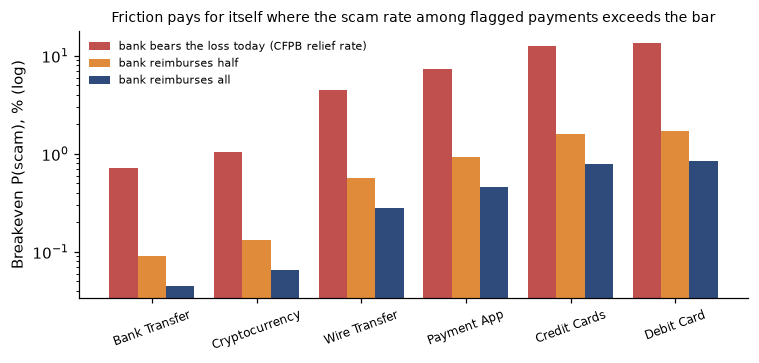

In [14]:
m = "Bank Transfer or Payment"
grid = pd.DataFrame([[100 * scam.breakeven_probability(LOSS[m], e, c, 1.0) for e in effs] for c in costs], index=[f"cost ${c}" for c in costs], columns=[f"stops {int(e*100)}%" for e in effs])
grid2 = pd.DataFrame([[100 * scam.breakeven_probability(LOSS[m], e, c, observed_share) for e in effs] for c in costs], index=[f"cost ${c}" for c in costs], columns=[f"stops {int(e*100)}%" for e in effs])
print(f"{m}: breakeven scam probability (%) if the bank bears all of the loss"); print(grid.round(3).to_string())
print(f"\n{m}: breakeven scam probability (%) if the bank bears only {observed_share:.1%} (today's monetary relief rate)"); print(grid2.round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 3.4))
ms = list(be.index); x = np.arange(len(ms)); w = 0.27
for i, (sname, col) in enumerate(zip(shares, [RED, ORANGE, NAVY])): ax.bar(x + (i - 1) * w, be[sname], w, color=col, label=sname)
ax.set_yscale("log"); ax.set_xticks(x, [s.replace(" or Payment", "").replace(" or Service", "") for s in ms], fontsize=8, rotation=20); ax.set_ylabel("Breakeven P(scam), % (log)")
ax.legend(frameon=False, fontsize=7); ax.set_title("Friction pays for itself where the scam rate among flagged payments exceeds the bar", fontsize=9)
plt.tight_layout(); plt.savefig(FIG + "breakeven.png"); plt.show()

In [15]:
# Persist tables for the app
import os; os.makedirs("../data/processed", exist_ok=True)
out.reset_index().to_csv("../data/processed/cfpb_scam_company.csv", index=False)
pd.Series({"observed_bank_share": observed_share, "pooled_monetary_relief": p0, "n_scam_complaints": int(overall.n)}).to_json("../data/processed/cfpb_scam_params.json")
LOSS.rename("loss_per_report_2024").reset_index().to_csv("../data/processed/loss_per_report_2024.csv", index=False)
len(out)

29

- **Who bears the loss moves the answer more than anything else.** For bank transfers at 25% effectiveness and $5 per flagged payment, breakeven is **0.72%** of flagged payments (about 1 in 140) if the bank bears only today's 6.3%, **0.09%** if it reimburses half, and **0.045%** (about 1 in 2,200) if it reimburses in full. Moving from today's share to full reimbursement lowers the bar 16-fold.
- **Friction pays first where the loss per scam is largest.** At the same assumptions, breakeven is 0.72% for bank transfers and 1.05% for crypto, but 12.6% for credit cards and 13.4% for debit cards: card friction would need roughly one flagged payment in eight to be a scam. Cards also come with chargeback protection.
- **Assumptions matter within a channel.** For bank transfers under today's loss share, the bar ranges from 0.18% (40% effective, $2) to 7.2% (10% effective, $20).
- **What to do with it:** add friction first to bank transfers and crypto purchases that look risky (new payee, large amount, unfamiliar device), and measure the scam rate among those flagged payments against the thresholds above. Where a bank bears little of the loss today, the case for friction rests mostly on customer harm and on regulatory or reimbursement exposure, which this model does not value.

## Findings
1. **Losses are concentrated:** 12.6% of loss reports hold at least 87.6% of the dollars; the median loss is $497 while the mean is 25 times larger.
2. **Bank transfers and crypto lead:** with wires, 70% of classified payment-method dollars, and $44,131 per bank-transfer report against $2,526 for credit cards.
3. **Totals and typical losses point at different channels:** social media for dollars, phone for the typical loss.
4. **Scam complaints mostly end with an explanation** (89.7%); monetary relief is 6.3% and varies from 0% to 20% across companies.
5. **Friction is worth it where loss per scam is high, and how much depends on who bears the loss:** the breakeven scam rate for bank transfers falls 16-fold if banks reimburse in full.

## Predictions versus outcomes
| # | Prediction | Outcome |
|---|---|---|
| 1 | Bank transfer, crypto and wire at least 60% of classified dollars in 2024 | **Right:** 70% |
| 2 | Reports above $10,000 hold at least 80% of dollars | **Right:** at least 87.6% |
| 3 | Highest total is not highest median; phone has the highest median | **Right:** social media (total) vs phone (median) |
| 4 | Bank transfer loss per report highest, more than 10 times credit cards | **Right:** $44,131 vs $2,526 (17 times) |
| 5 | Losses per 100,000 residents up at least 5 times, 2019 to 2024 | **Right:** 6.4 times |
| 6 | Under 10% monetary relief; at least 5 companies outside the 99.8% limits | **Right:** 6.3%; 15 companies |
| 7 | Bank-transfer breakeven under 0.5% if the bank bears all; over 1% at today's share | **Half right:** 0.045% and 0.72% at 25% effectiveness and $5 (above 1% only at 10% effectiveness) |

## Limits
- **Unverified consumer reports** in both sources; the FTC says reports cover only a fraction of scams, and the 2025 data book could not be located, so the latest year is 2024.
- **FTC figures were extracted from PDF tables**; payment method is classified for 18% of reports and contact method for 58%, and the FTC tables give no payment-method median.
- **CFPB scam tagging exists only in the money transfer product**; scams through checking accounts are not separately labeled. Company comparisons are among complainers and mix scam types; the funnel limits assume binomial variation and no extra heterogeneity.
- **The friction model gives breakeven thresholds, not forecasts:** no data on legitimate payment volumes, and effectiveness and cost are assumptions. It values only losses the bank bears, not customer harm, regulatory or reputational costs.
- **FTC loss per report mixes the whole population's payments with the bank's own customers;** a bank should substitute its own loss and flag-rate data.